# TX–RY knob-space minima analysis (81 × 81 scan)

This notebook imports the two acquisition files produced by
`tx_ry_scan_observables.ipynb`:

- `tx_ry_scan_81x81_z0.csv` — image at the DVF rest position (`z = 0`);
- `tx_ry_scan_81x81_zfocus.csv` — image retraced to `z = -142 mm`.

Each file contains a complete `81 × 81` scan of the mirror knobs:

- `TX` from `-1.0` to `+1.0` mm;
- `RY` from `-0.040` to `+0.040` mrad.

For every point the acquisition stores the centroid, beam sizes and intensity
with their fit uncertainties, plus the foci `q_x`, `q_y` and the astigmatism
`q_y - q_x` obtained from the caustic scan.

The observables are plotted following the layout of
`notebooks/optimization/CAX_optimization.ipynb`, but the red highlight now
marks the region that is **within the measurement uncertainty of the optimum**
instead of a fixed percentage of the observable range:

- for `sigma_x`, `sigma_y`, `Intensity` and `|astigmatism|`, the band is
  `value <= min(value) + err(min)`;
- for the centroids the target is zero, so the band is `|centroid| <= err`;
- for the objectives the observable uncertainties are propagated to the
  objective (delta method), then the same `min + err(min)` rule is applied.

The objective functions `f1 … f8` keep the exact definitions and normalisation
constants used in `CAX_optimization.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

In [2]:
DATA_DIR = Path.cwd()
if not (DATA_DIR / "tx_ry_scan_81x81_z0.csv").exists():
    DATA_DIR = Path("notebooks") / "knobspace_exploration"

Z0_PATH = DATA_DIR / "tx_ry_scan_81x81_z0.csv"
ZF_PATH = DATA_DIR / "tx_ry_scan_81x81_zfocus.csv"

N = 81
Z_FOCUS = -142.0  # mm

# Normalisation constants kept from CAX_optimization.ipynb
I0 = 10.0
DELTA = 500.0
SIGMAX_0 = 19.9  # um
SIGMAY_0 = 11.5  # um

print(Z0_PATH)
print(ZF_PATH)

/home/amici/repos/cax-control/notebooks/knobspace_exploration/tx_ry_scan_81x81_z0.csv
/home/amici/repos/cax-control/notebooks/knobspace_exploration/tx_ry_scan_81x81_zfocus.csv


## Load the scans and reshape them into 2D arrays

`point_index` runs as `ix * 81 + iy`, with `ix` indexing `TX` and `iy`
indexing `RY`, so a plain `(81, 81)` reshape gives arrays ordered `[TX, RY]`.

In [3]:
df_z0 = pd.read_csv(Z0_PATH).sort_values("point_index").reset_index(drop=True)
df_zf = pd.read_csv(ZF_PATH).sort_values("point_index").reset_index(drop=True)

assert len(df_z0) == N * N and len(df_zf) == N * N


def to_grid(frame, column):
    """Return a column as an (N, N) array ordered [TX, RY]."""
    return frame[column].to_numpy(dtype=float).reshape(N, N)


TX = to_grid(df_z0, "TX_mm")
RY = to_grid(df_z0, "RY_mrad")

assert np.allclose(TX, to_grid(df_zf, "TX_mm"))
assert np.allclose(RY, to_grid(df_zf, "RY_mrad"))

datasets = {
    "z = 0 mm": df_z0,
    f"z = {Z_FOCUS:g} mm": df_zf,
}

print(f"TX: {TX[0, 0]:+.3f} ... {TX[-1, 0]:+.3f} mm")
print(f"RY: {RY[0, 0]:+.4f} ... {RY[0, -1]:+.4f} mrad")
print(f"grid shape: {TX.shape}")

TX: -1.000 ... +1.000 mm
RY: -0.0400 ... +0.0400 mrad
grid shape: (81, 81)


In [23]:
np.sum(np.array(df_z0['duration_s']))/3600

6.998062940607714

## Uncertainty-aware highlight helpers

In [14]:
def _legend_proxy(label):
    return Patch(facecolor="red", alpha=0.3, label=label)


def add_minimum_error_band(ax, x, y, values, errors, *, legend=True):
    """Highlight values within the measurement error of the global minimum."""
    values = np.asarray(values, dtype=float)
    errors = np.asarray(errors, dtype=float)

    finite = np.where(np.isfinite(values), values, np.inf)
    idx = np.unravel_index(np.argmin(finite), values.shape)
    minimum = values[idx]
    error = 2*errors[idx]
    upper = minimum + error

    ax.contourf(x, y, values, levels=[minimum, upper], colors=["red"], alpha=0.3)

    if legend:
        ax.legend(
            handles=[_legend_proxy(f"$\\leq$ min + $2\\sigma$ ({error:.3g})")],
            loc="upper right",
            fontsize=8,
            frameon=True,
            facecolor="white",
            edgecolor="black",
        )
    return idx, minimum, error


def add_zero_error_band(ax, x, y, values, errors, *, legend=True):
    """Highlight values statistically consistent with zero."""
    values = np.asarray(values, dtype=float)
    errors = np.asarray(errors, dtype=float)
    mask = np.abs(values) <= np.abs(errors)

    if mask.any():
        ax.contourf(x, y, mask.astype(float), levels=[0.5, 1.5],
                    colors=["red"], alpha=0.3)

    if legend:
        ax.legend(
            handles=[_legend_proxy("$|c| \\leq \\sigma$")],
            loc="upper right",
            fontsize=8,
            frameon=True,
            facecolor="white",
            edgecolor="black",
        )
    return mask

## Observables

The six panels are paired as requested: centroid x/y, sigma x/y, and
intensity next to the absolute astigmatism. The intensity is plotted with a
negated sign so that every panel can use the same "minimum is best" convention.

In [19]:
OBSERVABLES = [
    ("centroid_x_um", "centroid_x_err_um", "centroid x", r"$x_c$ [$\mu$m]", "zero"),
    ("centroid_y_um", "centroid_y_err_um", "centroid y", r"$y_c$ [$\mu$m]", "zero"),
    ("sigma_x_um", "sigma_x_err_um", r"$\sigma_x$", r"$\sigma_x$ [$\mu$m]", "min"),
    ("sigma_y_um", "sigma_y_err_um", r"$\sigma_y$", r"$\sigma_y$ [$\mu$m]", "min"),
    ("Intensity", "Intensity_err", "Intensity", r"$-I$ [count / $\mu$m$^2$]", "neg_min"),
    ("astigmatism_mm", "astigmatism_err_mm", "Astigmatism", r"$|d|$ [mm]", "abs_min"),
]


def plot_observables(frame, title):
    fig, axs = plt.subplots(3, 2, figsize=(17, 16))
    fig.suptitle(title, fontsize=16)

    for ax, (column, err_column, name, clabel, mode) in zip(axs.flat, OBSERVABLES):
        values = to_grid(frame, column)
        errors = to_grid(frame, err_column)

        if mode == "neg_min":
            values = -values
        elif mode == "abs_min":
            values = np.abs(values)

        mesh = ax.pcolormesh(TX, RY, values, shading="auto")

        if mode == "zero":
            add_zero_error_band(ax, TX, RY, values, errors)
            idx = np.unravel_index(np.argmin(np.abs(values)), values.shape)
            tx_opt, ry_opt = TX[idx], RY[idx]
            inside = bool(np.abs(values[idx]) <= errors[idx])
            stats = (
                f"closest to 0 at ({tx_opt:+.3f}, {ry_opt:+.3f}) = "
                f"{values[idx]:+.4f}  ({'inside' if inside else 'outside'} $\\sigma$)"
            )
        else:
            idx, minimum, error = add_minimum_error_band(ax, TX, RY, values, errors)
            tx_opt, ry_opt = TX[idx], RY[idx]
            if mode == "neg_min":
                stats = (
                    f"max at ({tx_opt:+.3f}, {ry_opt:+.3f}) = "
                    f"{-values[idx]:.3f} $\\pm$ {error:.3f}"
                )
            else:
                stats = (
                    f"min at ({tx_opt:+.3f}, {ry_opt:+.3f}) = "
                    f"{minimum:.4f} $\\pm$ {error:.4f}"
                )
        if mode == 'zero':
            ax.contour(TX, RY, values, levels=10, colors="white", linewidths=0.2)
        else:
            levels = np.linspace(minimum+error, np.max(values), 15)
            ax.contour(TX, RY, values, levels=levels, colors="white", linewidths=0.2)
        ax.scatter(tx_opt, ry_opt, c="white", marker="d", s=30, zorder=5)
        ax.set_xlabel("TX [mm]")
        ax.set_ylabel("RY [mrad]")
        ax.set_title(f"{name}: {stats}")
        fig.colorbar(mesh, ax=ax, label=clabel)

    fig.tight_layout(rect=[0, 0, 1, 0.97])
    return fig

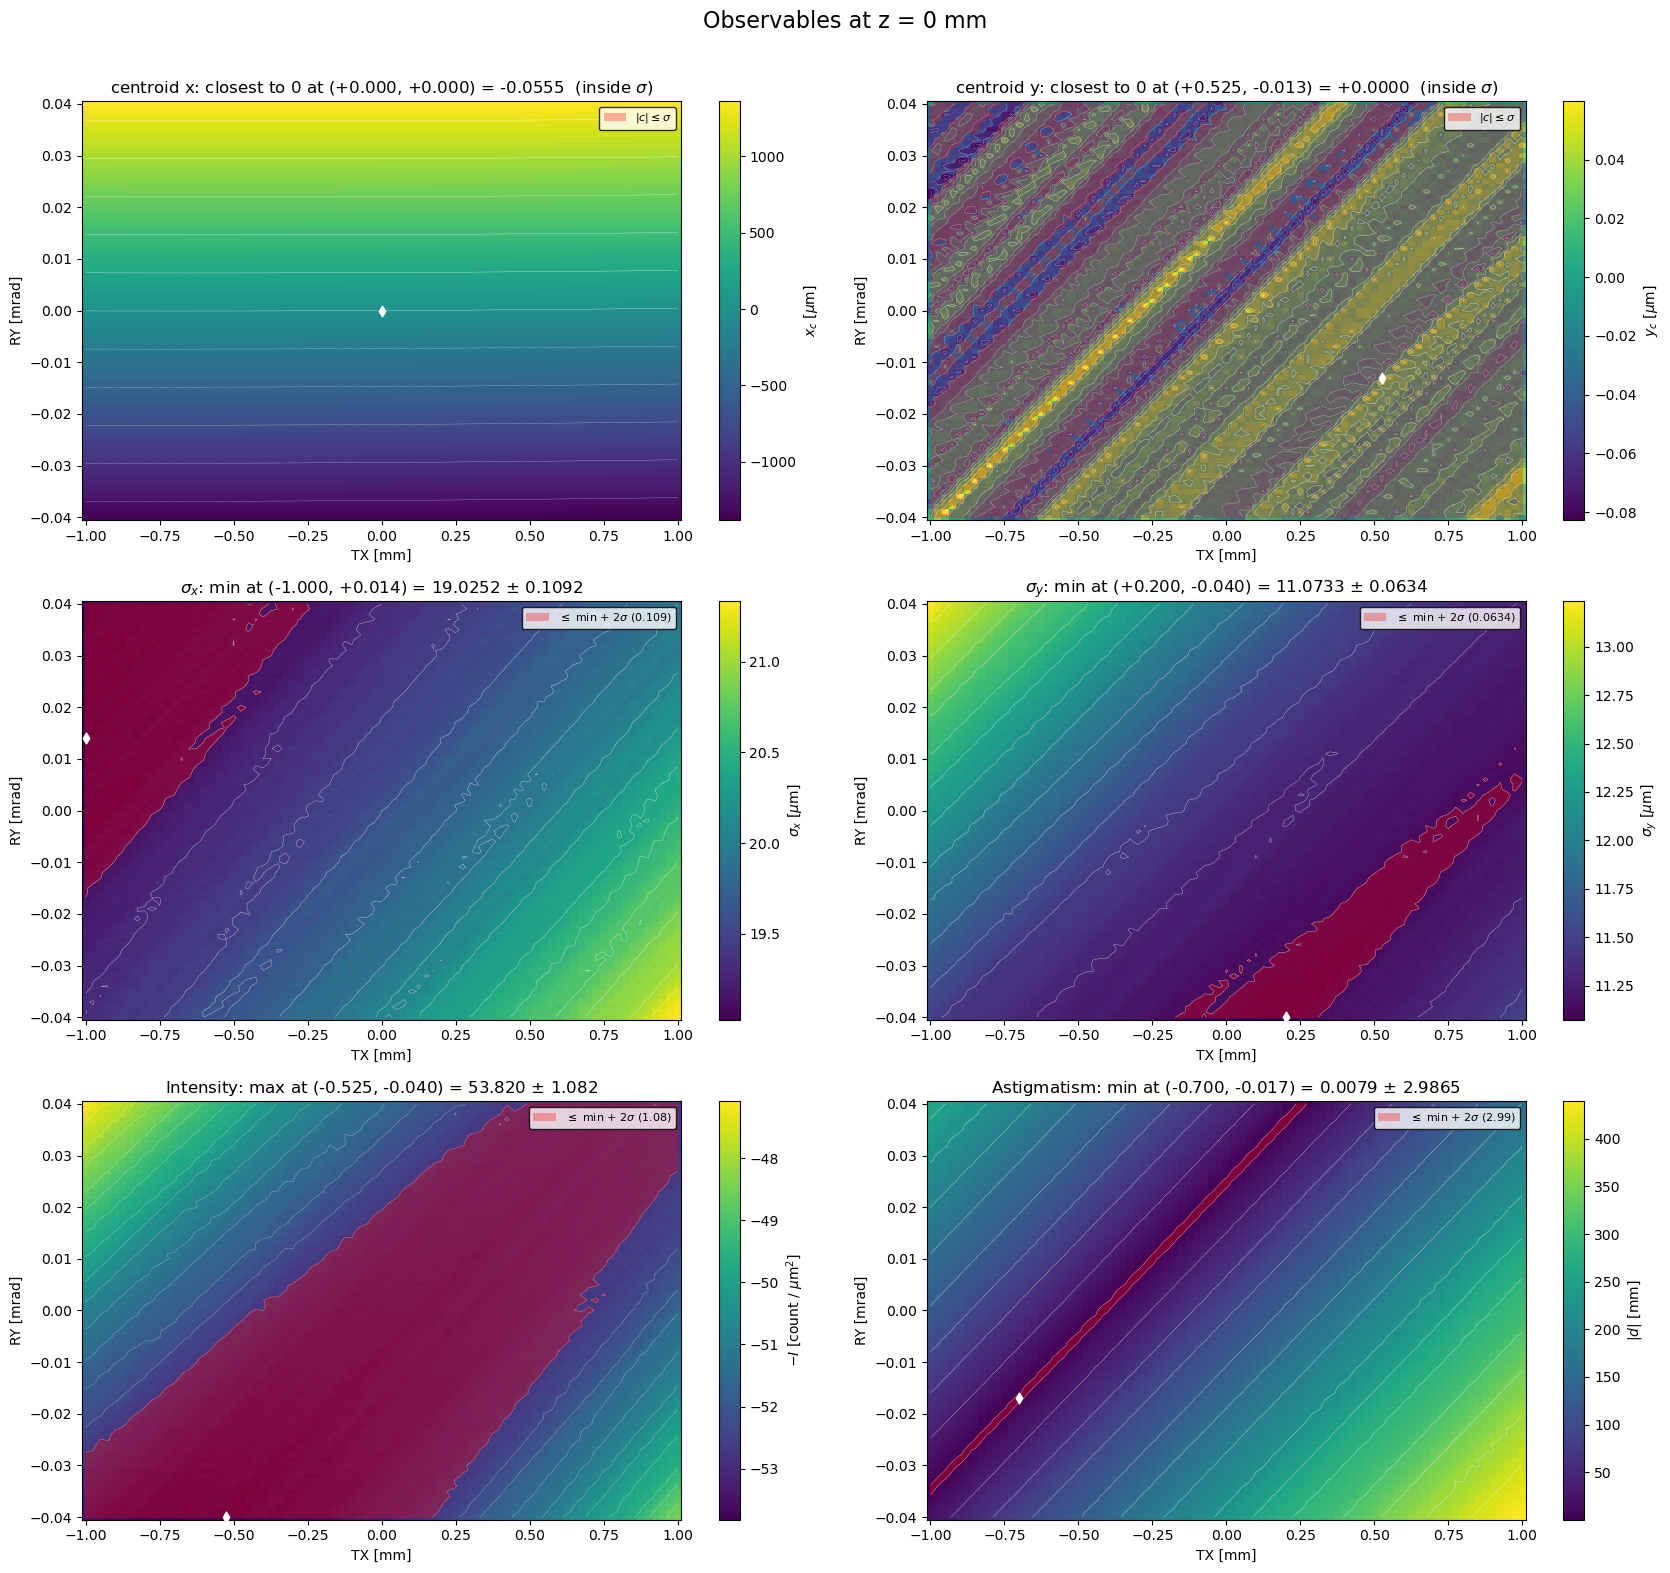

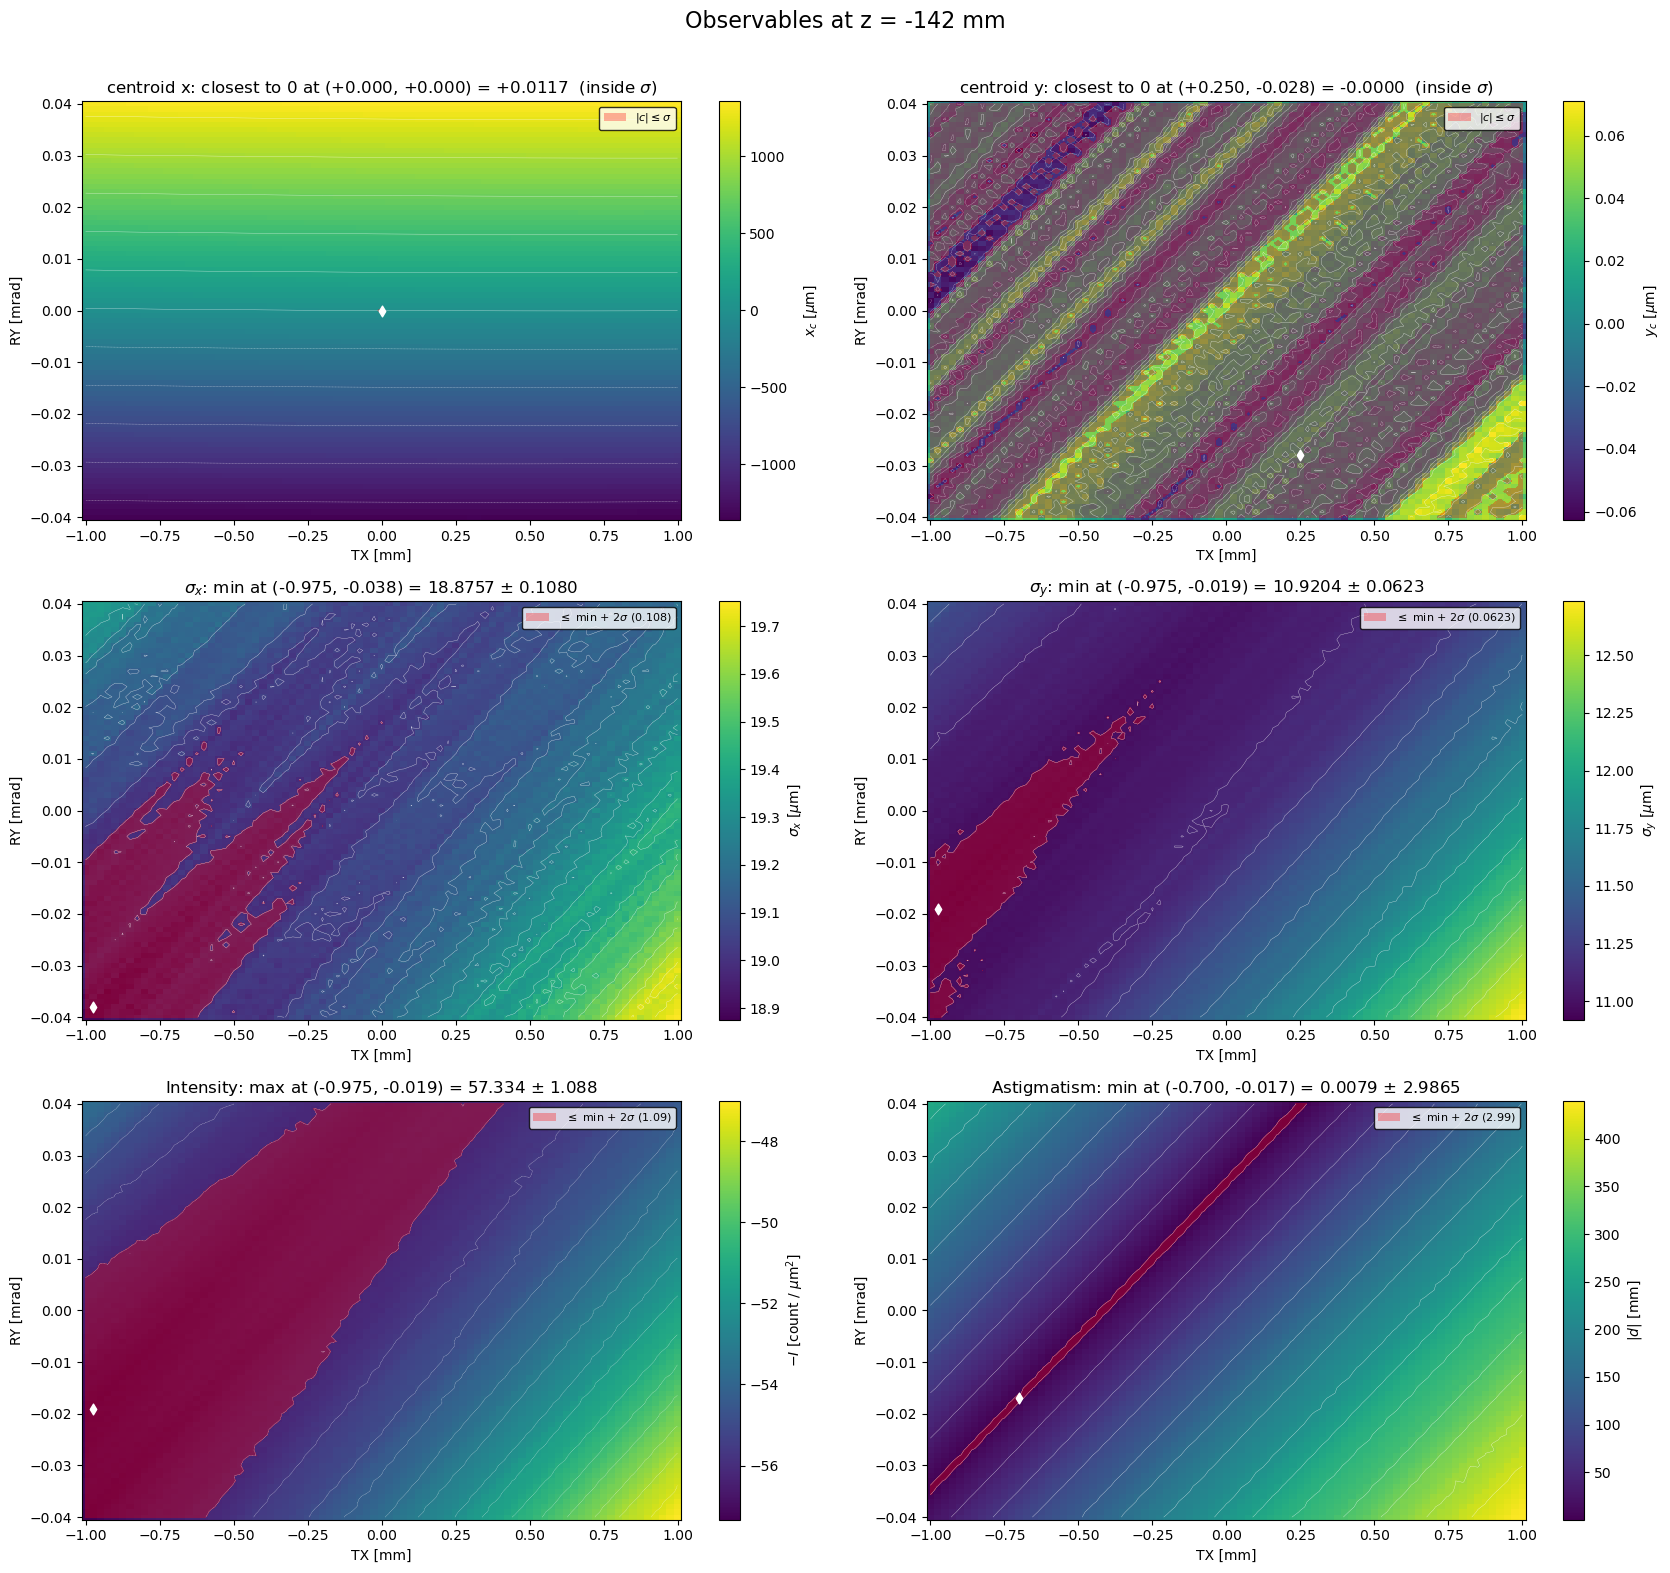

In [20]:
for z_label, frame in datasets.items():
    plot_observables(frame, f"Observables at {z_label}")
    plt.show()

## Objective functions

The definitions are unchanged from `CAX_optimization.ipynb`:

$$
\begin{aligned}
f_1 &= \frac{\sigma_x \sigma_y}{I}, &
f_2 &= \frac{\sigma_x}{\sigma_x^0} + \frac{\sigma_y}{\sigma_y^0}, &
f_3 &= -\frac{I}{I_0}, \\
f_4 &= f_2 + f_3, &
f_5 &= \frac{|d|}{\Delta}, &
f_6 &= f_2 + f_5, \\
f_7 &= f_3 + f_5, &
f_8 &= f_4 + f_5.
\end{aligned}
$$

The scan stores sigma in μm; it is converted to mm internally so the formulas
and the original normalisation constants remain untouched.

In [7]:
def objective_grids(frame):
    """Compute f1..f8 and their propagated uncertainties."""
    sx = to_grid(frame, "sigma_x_um") / 1000.0
    sy = to_grid(frame, "sigma_y_um") / 1000.0
    esx = to_grid(frame, "sigma_x_err_um") / 1000.0
    esy = to_grid(frame, "sigma_y_err_um") / 1000.0

    intensity = to_grid(frame, "Intensity")
    e_intensity = to_grid(frame, "Intensity_err")

    astig = to_grid(frame, "astigmatism_mm")
    e_astig = to_grid(frame, "astigmatism_err_mm")

    f1 = (1000.0) ** 2 * sx * sy / intensity
    f2 = 1000.0 * sx / SIGMAX_0 + 1000.0 * sy / SIGMAY_0
    f3 = -intensity / I0
    f4 = f2 + f3
    f5 = np.abs(astig) / DELTA
    f6 = f2 + f5
    f7 = f3 + f5
    f8 = f4 + f5

    # Delta-method propagation assuming independent observables.
    e1 = np.abs(f1) * np.sqrt(
        (esx / sx) ** 2 + (esy / sy) ** 2 + (e_intensity / intensity) ** 2
    )
    e2 = np.sqrt((1000.0 * esx / SIGMAX_0) ** 2 + (1000.0 * esy / SIGMAY_0) ** 2)
    e3 = e_intensity / I0
    e4 = np.sqrt(e2 ** 2 + e3 ** 2)
    e5 = e_astig / DELTA
    e6 = np.sqrt(e2 ** 2 + e5 ** 2)
    e7 = np.sqrt(e3 ** 2 + e5 ** 2)
    e8 = np.sqrt(e2 ** 2 + e3 ** 2 + e5 ** 2)

    objectives = {"f1": f1, "f2": f2, "f3": f3, "f4": f4,
                  "f5": f5, "f6": f6, "f7": f7, "f8": f8}
    errors = {"f1": e1, "f2": e2, "f3": e3, "f4": e4,
              "f5": e5, "f6": e6, "f7": e7, "f8": e8}
    return objectives, errors

In [26]:
OBJECTIVE_LABELS = {
    "f1": r"$\sigma_x\sigma_y/I$",
    "f2": r"$\sigma_x/\sigma_x^0 + \sigma_y/\sigma_y^0$",
    "f3": r"$-I/I_0$",
    "f4": r"$f_2(\sigma_x, \sigma_y) + f_3(I)$",
    "f5": r"$|d|/\Delta$",
    "f6": r"$f_2(\sigma_x, \sigma_y) + f_5(d)$",
    "f7": r"$f_3(I) + f_5(d)$",
    "f8": r"$f_4(\sigma_x, \sigma_y, I) + f_5(d)$",
}

OBJECTIVE_NAMES = {
    "f1": "Mixed geometric intensity",
    "f2": "Geometric",
    "f3": "Intensity",
    "f4": "Geometric and intensity",
    "f5": "Astigmatism",
    "f6": "Geometric and astigmatism",
    "f7": "Intensity and astigmatism",
    "f8": "Geometric, intensity and astigmatism",
}

ORDER = [f"f{i}" for i in range(1, 9)]


def plot_objectives(frame, title):
    objectives, errors = objective_grids(frame)
    fig, axs = plt.subplots(4, 2, figsize=(17, 24))
    fig.suptitle(title, fontsize=16)

    for ax, key in zip(axs.flat, ORDER):
        values = objectives[key]
        err = errors[key]

        mesh = ax.pcolormesh(TX, RY, values, shading="auto")
        idx, minimum, uncertainty = add_minimum_error_band(
            ax, TX, RY, values, err, legend=(key == "f1")
        )
        tx_opt, ry_opt = TX[idx], RY[idx]

        levels = np.linspace(minimum+uncertainty, np.max(values), 15)
        ax.contour(TX, RY, values, levels=levels, colors="white", linewidths=0.2)
        ax.scatter(tx_opt, ry_opt, c="white", marker="d", s=30, zorder=5)
        ax.set_xlabel("TX [mm]")
        ax.set_ylabel("RY [mrad]")
        ax.set_title(
            f"{OBJECTIVE_NAMES[key]} (${key}$): min at "
            f"({tx_opt:+.3f}, {ry_opt:+.3f}) = {minimum:.4f} $\\pm$ {uncertainty:.4f}"
        )
        fig.colorbar(mesh, ax=ax, label=OBJECTIVE_LABELS[key])

    fig.tight_layout(rect=[0, 0, 1, 0.98])
    return fig

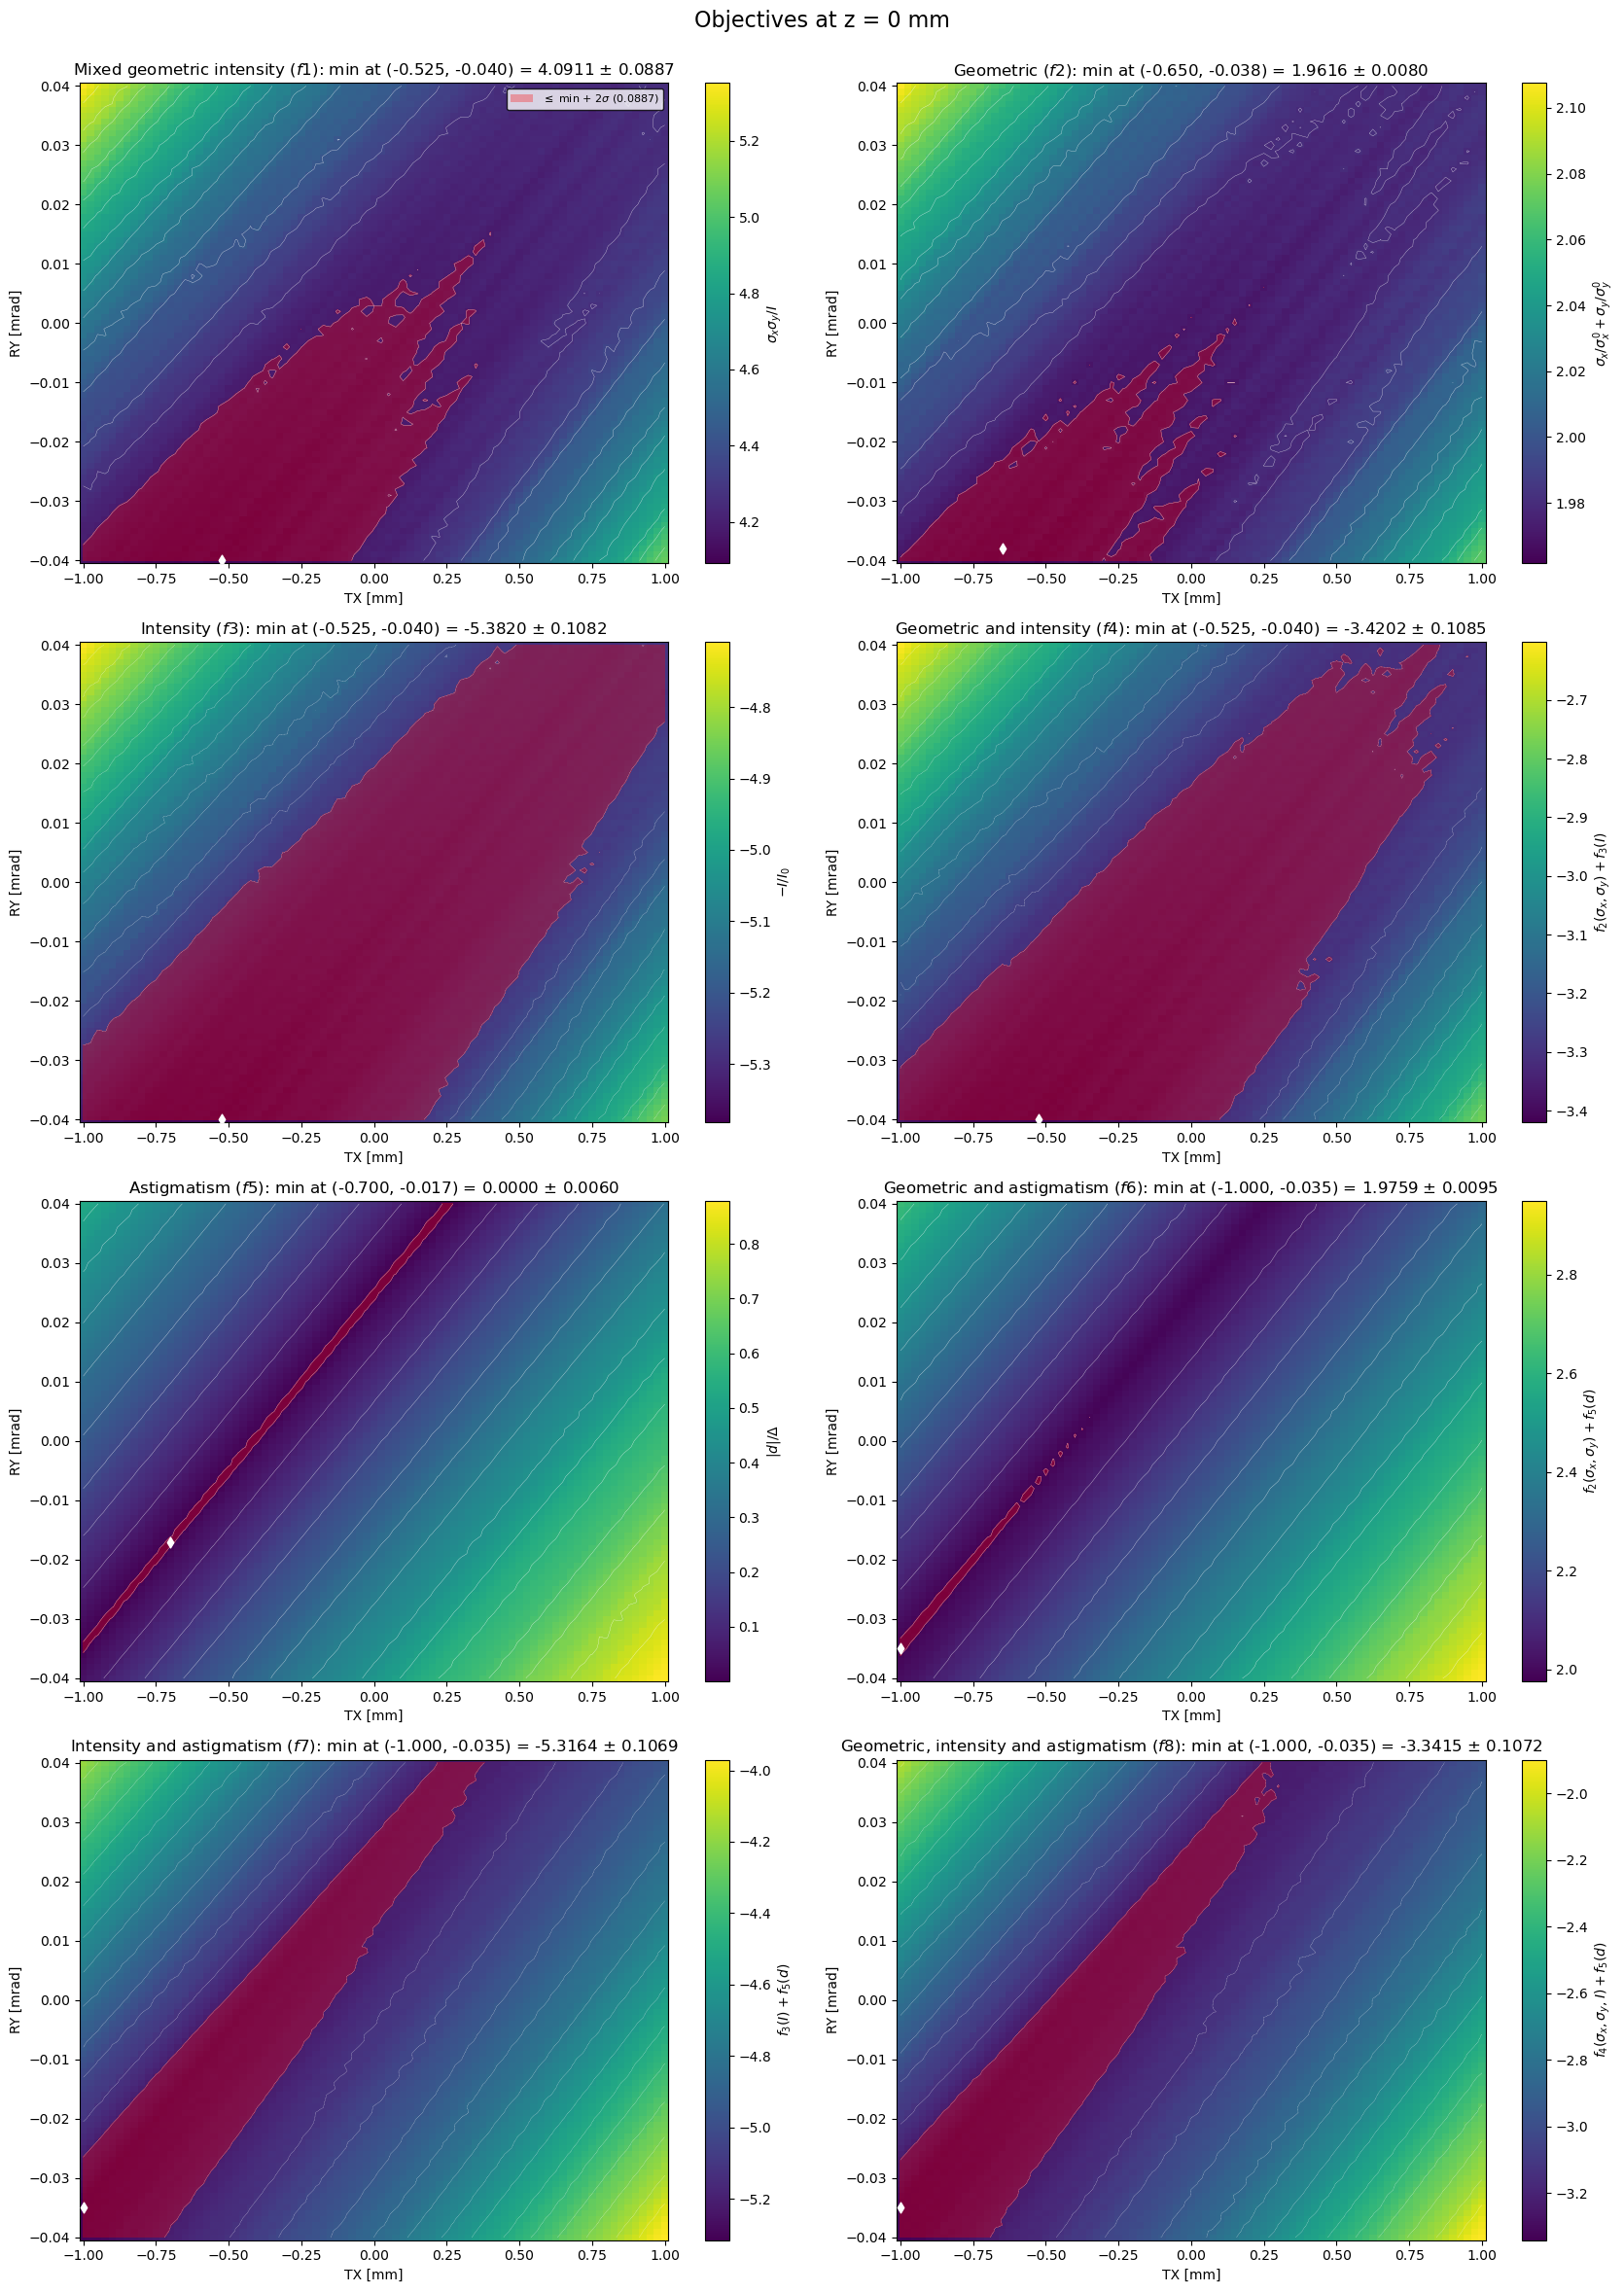

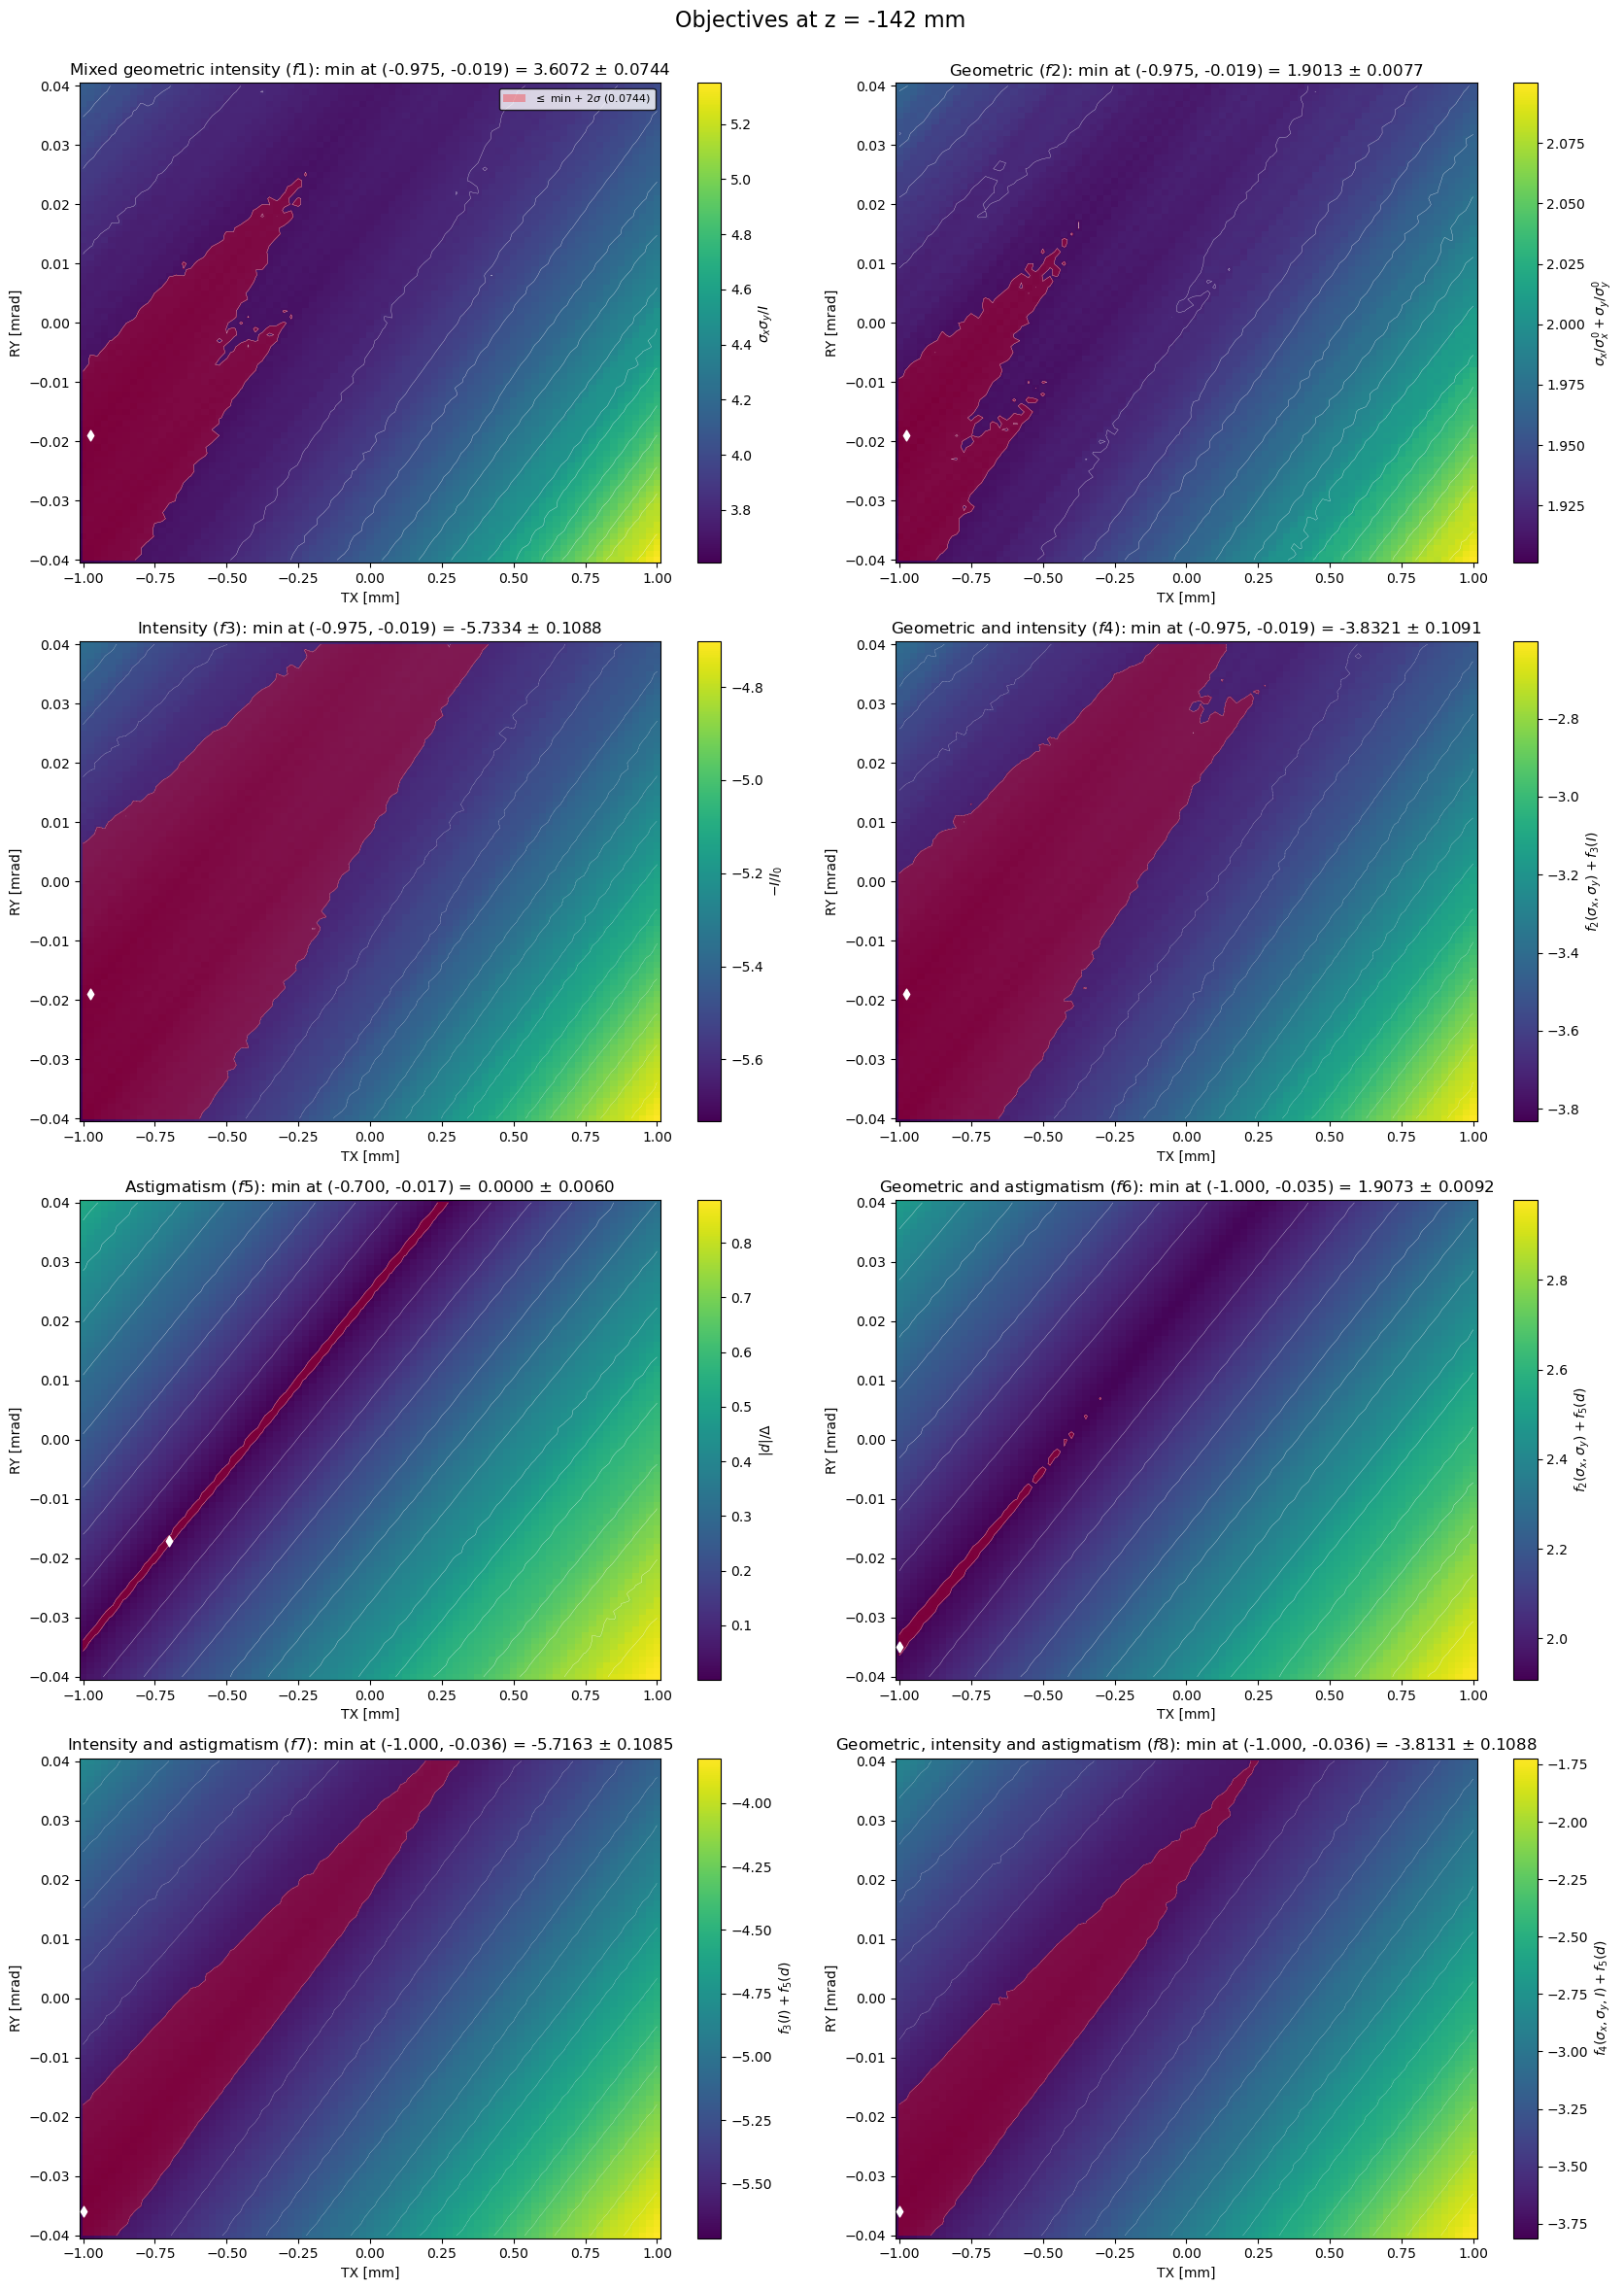

In [27]:
for z_label, frame in datasets.items():
    plot_objectives(frame, f"Objectives at {z_label}")
    plt.show()

## Minima summary

In [10]:
def observable_minima(frame):
    rows = []
    for column, err_column, name, _, mode in OBSERVABLES:
        values = to_grid(frame, column)
        errors = to_grid(frame, err_column)

        if mode == "neg_min":
            values = -values
        elif mode == "abs_min":
            values = np.abs(values)

        if mode == "zero":
            idx = np.unravel_index(np.argmin(np.abs(values)), values.shape)
            criterion = "closest to 0"
            value = values[idx]
            error = errors[idx]
        else:
            idx = np.unravel_index(np.argmin(values), values.shape)
            criterion = "maximum" if mode == "neg_min" else "minimum"
            value = -values[idx] if mode == "neg_min" else values[idx]
            error = errors[idx]

        rows.append({
            "observable": name,
            "criterion": criterion,
            "TX [mm]": TX[idx],
            "RY [mrad]": RY[idx],
            "value": value,
            "error": error,
        })
    return pd.DataFrame(rows)


def objective_minima(frame):
    objectives, errors = objective_grids(frame)
    rows = []
    for key in ORDER:
        values = objectives[key]
        idx = np.unravel_index(np.argmin(values), values.shape)
        rows.append({
            "objective": key,
            "TX [mm]": TX[idx],
            "RY [mrad]": RY[idx],
            "minimum": values[idx],
            "propagated error": errors[key][idx],
        })
    return pd.DataFrame(rows)

In [11]:
for z_label, frame in datasets.items():
    print(f"\n{'=' * 70}\n{z_label}\n{'=' * 70}")
    print("\nObservable optima")
    display(observable_minima(frame).round(4))
    print("\nObjective minima")
    display(objective_minima(frame).round(4))


z = 0 mm

Observable optima


,observable,criterion,TX [mm],RY [mrad],value,error
0,centroid x,closest to 0,0.000,0.000,-0.0555,0.0734
1,centroid y,closest to 0,0.525,-0.013,0.0000,0.0416
2,$\sigma_x$,minimum,-1.000,0.014,19.0252,0.0546
3,$\sigma_y$,minimum,0.200,-0.040,11.0733,0.0317
4,Intensity,maximum,-0.525,-0.040,53.8201,0.5412
5,Astigmatism,minimum,-0.700,-0.017,0.0079,1.4932



Objective minima


,objective,TX [mm],RY [mrad],minimum,propagated error
0,f1,-0.525,-0.040,4.0911,0.0443
1,f2,-0.650,-0.038,1.9616,0.0040
2,f3,-0.525,-0.040,-5.3820,0.0541
3,f4,-0.525,-0.040,-3.4202,0.0543
4,f5,-0.700,-0.017,0.0000,0.0030
5,f6,-1.000,-0.035,1.9759,0.0047
6,f7,-1.000,-0.035,-5.3164,0.0535
7,f8,-1.000,-0.035,-3.3415,0.0536



z = -142 mm

Observable optima


,observable,criterion,TX [mm],RY [mrad],value,error
0,centroid x,closest to 0,0.000,0.000,0.0117,0.0712
1,centroid y,closest to 0,0.250,-0.028,-0.0000,0.0434
2,$\sigma_x$,minimum,-0.975,-0.038,18.8757,0.0540
3,$\sigma_y$,minimum,-0.975,-0.019,10.9204,0.0312
4,Intensity,maximum,-0.975,-0.019,57.3343,0.5440
5,Astigmatism,minimum,-0.700,-0.017,0.0079,1.4932



Objective minima


,objective,TX [mm],RY [mrad],minimum,propagated error
0,f1,-0.975,-0.019,3.6072,0.0372
1,f2,-0.975,-0.019,1.9013,0.0038
2,f3,-0.975,-0.019,-5.7334,0.0544
3,f4,-0.975,-0.019,-3.8321,0.0545
4,f5,-0.700,-0.017,0.0000,0.0030
5,f6,-1.000,-0.035,1.9073,0.0046
6,f7,-1.000,-0.036,-5.7163,0.0543
7,f8,-1.000,-0.036,-3.8131,0.0544


In [12]:
comparison = pd.concat(
    {
        z_label: objective_minima(frame).set_index("objective")
        for z_label, frame in datasets.items()
    },
    axis=1,
)
display(comparison.round(4))

z = 0 mm                                    z = -142 mm            \
           TX [mm] RY [mrad] minimum propagated error     TX [mm] RY [mrad]   
objective                                                                     
f1          -0.525    -0.040  4.0911           0.0443      -0.975    -0.019   
f2          -0.650    -0.038  1.9616           0.0040      -0.975    -0.019   
f3          -0.525    -0.040 -5.3820           0.0541      -0.975    -0.019   
f4          -0.525    -0.040 -3.4202           0.0543      -0.975    -0.019   
f5          -0.700    -0.017  0.0000           0.0030      -0.700    -0.017   
f6          -1.000    -0.035  1.9759           0.0047      -1.000    -0.035   
f7          -1.000    -0.035 -5.3164           0.0535      -1.000    -0.036   
f8          -1.000    -0.035 -3.3415           0.0536      -1.000    -0.036   

                                    
          minimum propagated error  
objective                           
f1         3.6072           0.0372  
f2         1.9013           0.0038  
f3        -5.7334           0.0544  
f4        -3.8321           0.0545  
f5         0.0000           0.0030  
f6         1.9073           0.0046  
f7        -5.7163           0.0543  
f8        -3.8131           0.0544

In [13]:
print("Objective minima comparison\n" + "=" * 60)
for key in ["f2", "f4", "f8"]:
    print(f"\n{key}")
    for z_label, frame in datasets.items():
        objectives, errors = objective_grids(frame)
        values = objectives[key]
        idx = np.unravel_index(np.argmin(values), values.shape)
        print(
            f"  {z_label:>12s}: ({TX[idx]:+.3f} mm, {RY[idx]:+.3f} mrad) = "
            f"{values[idx]:.4f} +/- {errors[key][idx]:.4f}"
        )

Objective minima comparison

f2
      z = 0 mm: (-0.650 mm, -0.038 mrad) = 1.9616 +/- 0.0040
   z = -142 mm: (-0.975 mm, -0.019 mrad) = 1.9013 +/- 0.0038

f4
      z = 0 mm: (-0.525 mm, -0.040 mrad) = -3.4202 +/- 0.0543
   z = -142 mm: (-0.975 mm, -0.019 mrad) = -3.8321 +/- 0.0545

f8
      z = 0 mm: (-1.000 mm, -0.035 mrad) = -3.3415 +/- 0.0536
   z = -142 mm: (-1.000 mm, -0.036 mrad) = -3.8131 +/- 0.0544
